In [2]:
import json
import os
import cv2
import json
import fastwer
import shutil
import pyewts
import random
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
from glob import glob
from pathlib import Path
from evaluate import load
from natsort import natsorted
from Modules import PatchedLineDetection, PatchedPerigLayoutDetection, OnnxInference, KerasInference
from IPython.display import Image as ShowImage
from Exporter import PageXMLExporter
from Utils import create_dir, get_line_images_from_line_data, rotate_from_angle, get_random_color, read_lines_from_file, get_file_name, get_lines_from_page, prepare_ocr_image2

d:\Github\OCR-Inference\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
def show_image(image: np.array, cmap: str = "") -> None:
    plt.figure(figsize=(24, 13))
    #plt.axis("off")
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

def show_overlay(image: np.array, mask: np.array, alpha=0.4):
    plt.figure(figsize=(18, 9))
    plt.axis("off")
    plt.imshow(image)
    plt.imshow(mask, alpha=alpha)

In [97]:
converter = pyewts.pyewts()
cer_scorer = load("cer")

layout_config = "Models\LayoutModels\LA_v2_2024-1-22_6-36\model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)


ocr_config = "Models/OCRModels/LhasaKanjurEaster/v2/model_config.json"
ocr_inference = OnnxInference(config_file=ocr_config)
keras_inf = KerasInference(ocr_config)

KeyError: 'input_layer'

In [7]:
data_path = "D:/Datasets/Tibetan/LhasaKanjur"

images = natsorted(glob(f"{data_path}/pages/*.jpg"))
label_paths = natsorted(glob(f"{data_path}/transcriptions/*.txt"))

print(f"Images: {len(images)}, Transcriptions: {len(label_paths)}")

Images: 94160, Transcriptions: 94160


In [9]:
# get filenames from pages with rare stacks (n < 400)
rare_stack_file = "D:/Datasets/Tibetan/LhasaKanjur/rare_stack_pages_lhasa.txt"
rage_stack_pages = read_lines_from_file(rare_stack_file)
rare_stack_pages =  [x.replace("\n", "") for x in rage_stack_pages]
rare_stack_pages[0]

'90-1-212b'

In [10]:
rare_stack_labels = [f"{data_path}/transcriptions\\{x}.txt" for x in rage_stack_pages]
rare_stack_labels =  [x.replace("\n", "") for x in rare_stack_labels]
print(rare_stack_labels[0])

D:/Datasets/Tibetan/LhasaKanjur/transcriptions\90-1-212b.txt


In [11]:
rare_stack_labels[:10]

['D:/Datasets/Tibetan/LhasaKanjur/transcriptions\\90-1-212b.txt',
 'D:/Datasets/Tibetan/LhasaKanjur/transcriptions\\34-1-407b.txt',
 'D:/Datasets/Tibetan/LhasaKanjur/transcriptions\\81-1-94b.txt',
 'D:/Datasets/Tibetan/LhasaKanjur/transcriptions\\81-1-427b.txt',
 'D:/Datasets/Tibetan/LhasaKanjur/transcriptions\\70-1-491a.txt',
 'D:/Datasets/Tibetan/LhasaKanjur/transcriptions\\86-1-443b.txt',
 'D:/Datasets/Tibetan/LhasaKanjur/transcriptions\\93-1-456b.txt',
 'D:/Datasets/Tibetan/LhasaKanjur/transcriptions\\87-1-124a.txt',
 'D:/Datasets/Tibetan/LhasaKanjur/transcriptions\\93-1-171a.txt',
 'D:/Datasets/Tibetan/LhasaKanjur/transcriptions\\71-1-349a.txt']

91801
D:/Datasets/Tibetan/LhasaKanjur/transcriptions\97-1-259a.txt
༄༅། །སྤེལ་བ་ནི། འདི་ལྟ་སྟེ། གང་མེད་པ་ལས་གཅིག་ཏུ་བྱུང་བ་དང༌། གཅིག་ལས་གསུམ་དང༌། ལྔ་དང༌། བཞི་བཅུ་དང༌། འབུམ་སྡེ་དང༌། བྱེ་བ་
དང༌། ས་ཡར་འཕེལ་བས་ཐམས་ཅད་ཤེས་པར་བྱེད་པའོ། །གང་ཤེས་པར་བྱེད་པ་ནི། འདི་ལྟ་སྟེ། མིང་བཀླག་པ་དང༌། ཚིག་བཀླག་པ་དང༌། གཟུགས་བཀླགས་
པ་དང༌། དོན་བཀླག་པ་དང༌། སྒྲ་བཀླག་པ་དང༌། གཅིག་བཀླག་པ་དང༌། མང་པོ་བཀླག་པ་དང༌། གཅིག་མང་པོར་བཀླག་པ་དང༌། མང་པོ་གཅིག་ཏུ་བཀླག་པ་དང༌། གཅིག་
དང༌། མང་པོ་ཐ་དད་པར་བཀླག་པའོ། །ཡང་ལང་ཀའི་བདག་པོ། འདི་ལ་ཡི་གེའི་སྒོ་གང་ཞེ་ན། འདི་ལྟ་སྟེ། ཡི་གེའི་སྒོ་དང༌། ཚིག་གི་སྒོ་དང༌། དོན་གྱི་སྒོ་དང༌། དབྱངས་
ཀྱི་སྒོ་དང༌། གཟུངས་ཀྱི་སྒོ་རྣམས་སུ་རིག་པར་བྱའོ། །ལང་ཀའི་བདག་པོ། དེ་ལ་ཡི་གེའི་སྒོ་གང་ཞེ་ན། གང་གིས་གང་ལ་བྲིས་པའོ། །ཚིག་གི་སྒོ་གང་ཞེ་ན། གང་ཡི་
གེའོ། །དོན་གྱི་སྒོ་གང་ཞེ་ན། གང་ཚིག་གི་ཚོགས་སོ། །དབྱངས་ཀྱི་སྒོ་གང་ཞེ་ན། གང་ཡི་གེ་བཅུ་དྲུག་གོ །ལང་ཀའི་བདག་པོ། ཡི་གེ་བཅུ་དྲུག་ཀྱང་གང་ཞེ་ན། འགར་
དང༌། ཅྭང་འབའ་ཞིག་ཏུ་ཤེས་པར་བྱའོ། །དེ་ནི་རིང་པོ་དང༌། ཐུང་ངུ་ཉིད་དུ་རིག་པར་བྱའོ། །གང་ཐུང་ངུ་དང༌། རིང་པོ་དེ་ཉིད་ལས་དབྱངས་ཀྱི་ཡན་ལག་དྲུག་བྱུང

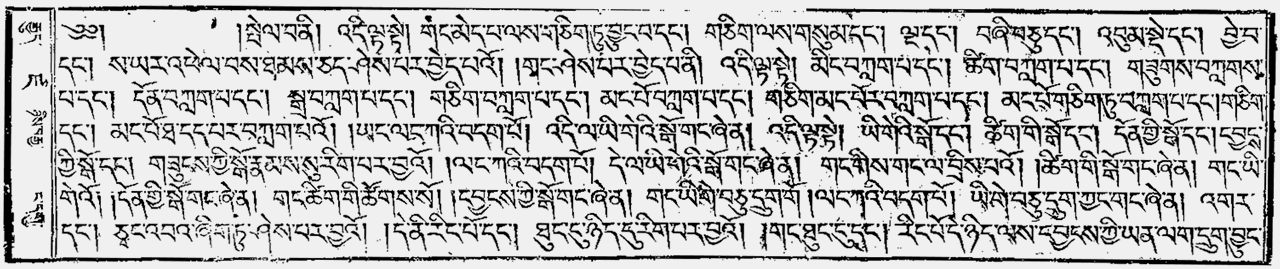

In [32]:
r_idx = 234
r_lbl = rare_stack_labels[r_idx]
idx = label_paths.index(r_lbl)
print(idx)
print(label_paths[idx])
ref_label = get_lines_from_page(label_paths[idx])

for lbl in ref_label:
    print(lbl)

ShowImage(images[idx])


(269, 1280, 3)


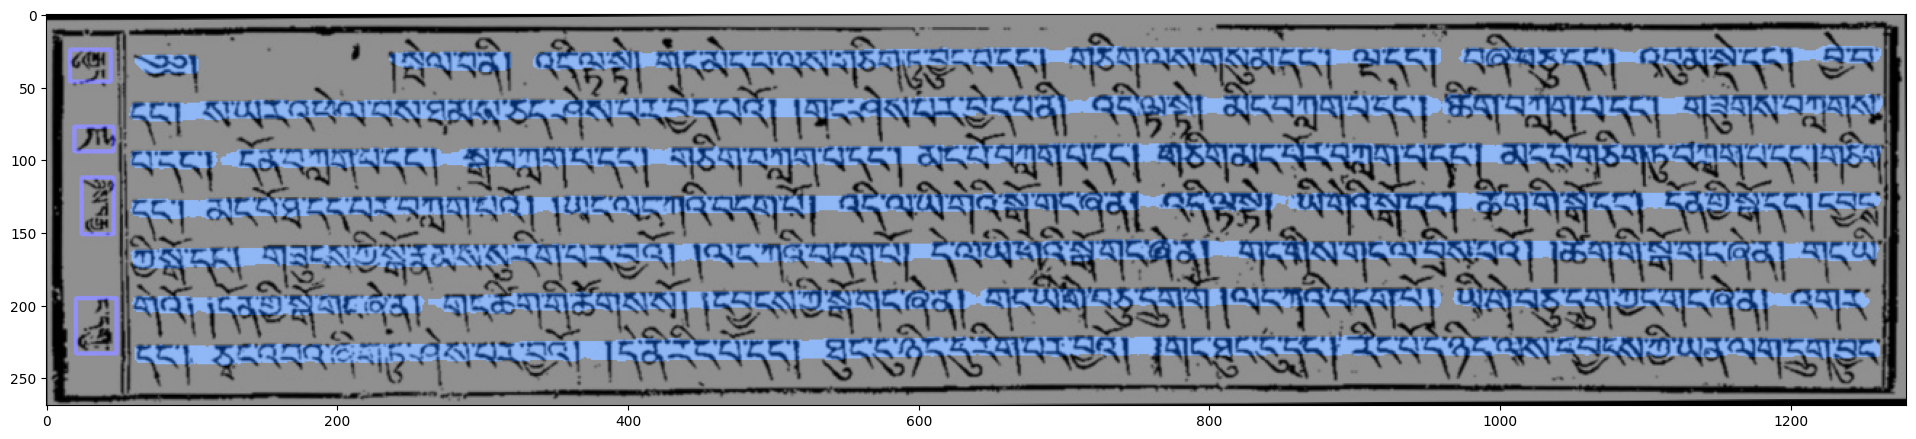

In [33]:
try:
  image_name = os.path.basename(images[idx]).split(".")[0]
  _img = cv2.imread(images[idx])

  print(_img.shape)

except FileExistsError as e:
    print.error(f"Cant read file at provided location: {images[idx]}, {e}")

# layout_inference
layout_data, preview_img = layout_inference.predict(_img)

show_image(preview_img)

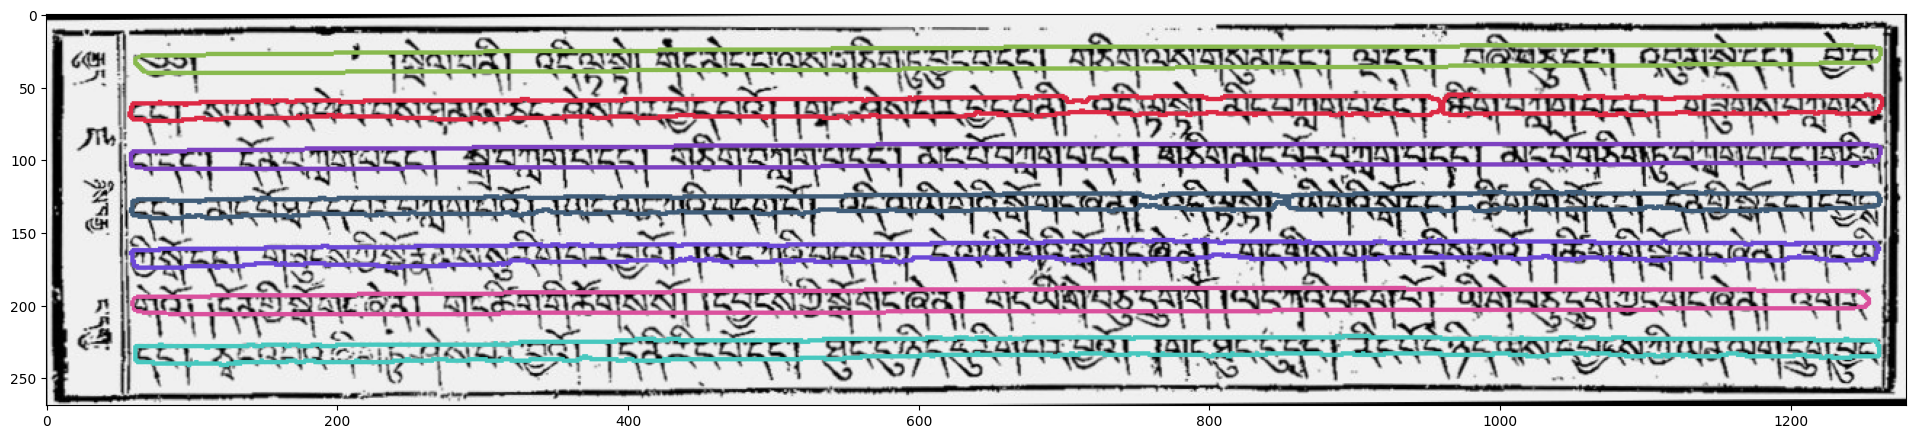

In [34]:
sorted_layout_data = layout_inference.sort_lines(layout_data, threshold=20, calculate=False)
r_img = rotate_from_angle(_img, layout_data.rotation)
prev_img = r_img.copy()
color = get_random_color()

for line_data in layout_data.lines:
    color = get_random_color()
    cv2.drawContours(prev_img,[line_data.contour],contourIdx=-1,color=color,thickness=2)

show_image(prev_img) 

In [48]:
from DataClasses import LineData
from Utils import calculate_dilate_iterations, binarize_line

def get_line_images_from_line_data2(
    image: np.array,
    line_data: list[LineData],
    dilate_kernel: int = 24,
    dilate_iterations: int = 1,
    binarize: bool = False,
    calculate_iterations: bool = True
):
    line_images = []

    # enforce a default value in case the somebody passes 0 as value
    if dilate_kernel == 0:
        dilate_kernel = 24

    
    for line in line_data:
        image_mask = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)
        cv2.drawContours(
            image_mask, [line.contour], contourIdx=0, color=(255, 255, 255), thickness=-1
        )
        if calculate_iterations:
            dilate_iterations = calculate_dilate_iterations(line, dilate_kernel)

        dilated1 = cv2.dilate(
            image_mask,
            kernel=(dilate_kernel+20, dilate_kernel+20),
            iterations=dilate_iterations,
            borderValue=0,
            anchor=(-1, 0),
            borderType=cv2.BORDER_DEFAULT,
        )
        dilated2 = cv2.dilate(
            image_mask,
            kernel=(dilate_kernel, dilate_kernel,
            iterations=dilate_iterations,
            borderValue=0,
            anchor=(0, 1),
            borderType=cv2.BORDER_DEFAULT,
        )
        combined = cv2.add(dilated1, dilated2)
        image_masked = cv2.bitwise_and(image, image, mask=combined)

        cropped_img = np.delete(
            image_masked, np.where(~image_masked.any(axis=1))[0], axis=0
        )
        cropped_img = np.delete(
            cropped_img, np.where(~cropped_img.any(axis=0))[0], axis=1
        )
        

        # print(cropped_img.shape)

        if binarize:
            # indices = np.where(cropped_img[:, :, 1] == 0)
            # clear = cropped_img.copy()
            # clear[indices[0], indices[1], :] = [255, 255, 255]
            # clear_bw = cv2.cvtColor(clear, cv2.COLOR_BGR2GRAY)
            # _, thresh = cv2.threshold(clear_bw, 170, 255, cv2.THRESH_BINARY)
            # line_images.append(thresh)
            cropped_img = binarize_line(cropped_img)
            line_images.append(cropped_img)
        else:
            line_images.append(cropped_img)

    return line_images

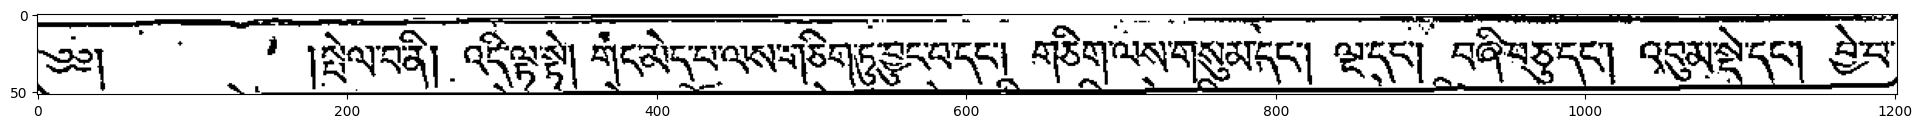

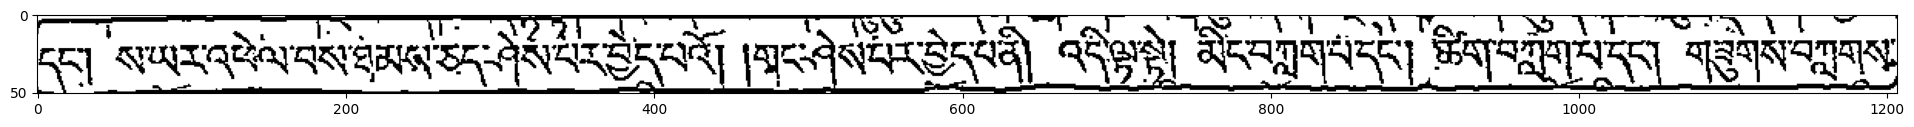

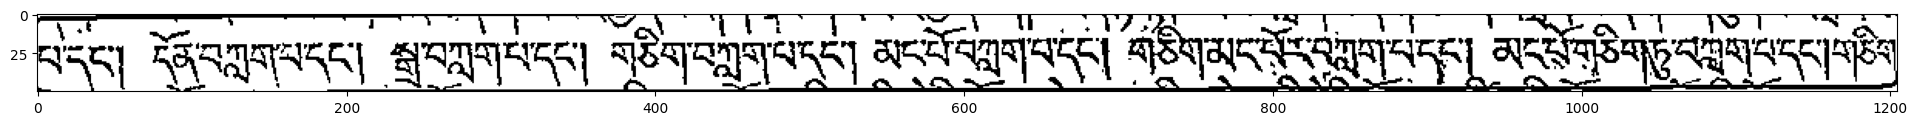

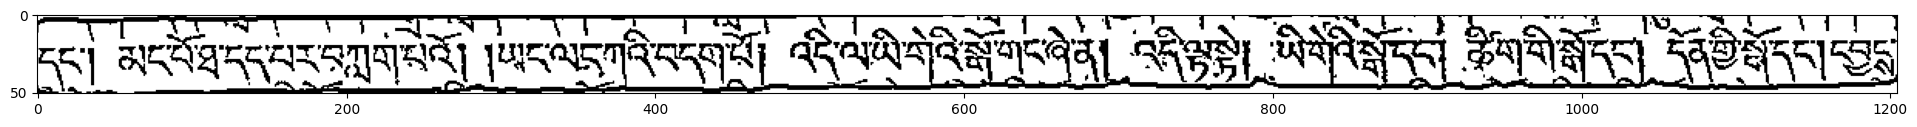

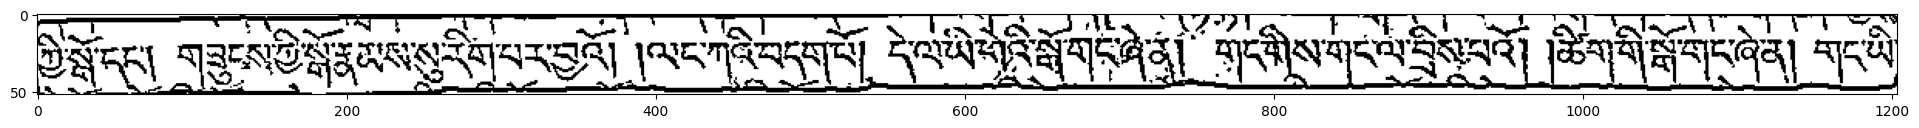

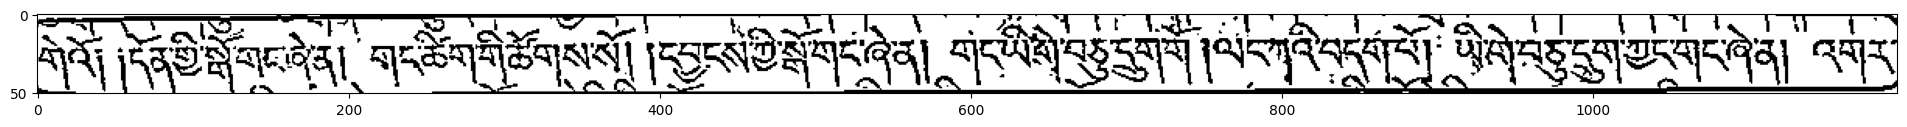

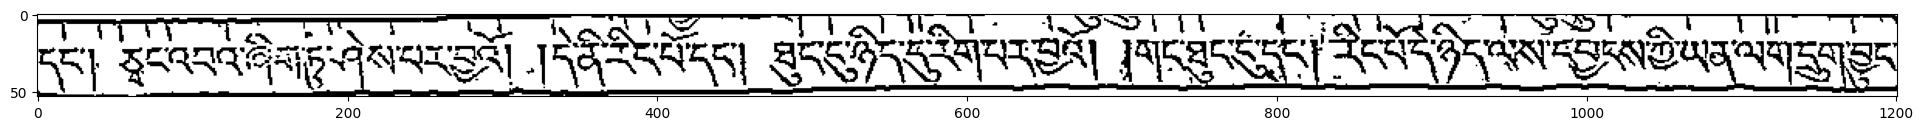

In [78]:
layout_line_images = get_line_images_from_line_data2(r_img, sorted_layout_data.lines, dilate_kernel=24, dilate_iterations=16, calculate_iterations=False, binarize=True)
for idx, img in enumerate(layout_line_images):
    show_image(layout_line_images[idx])

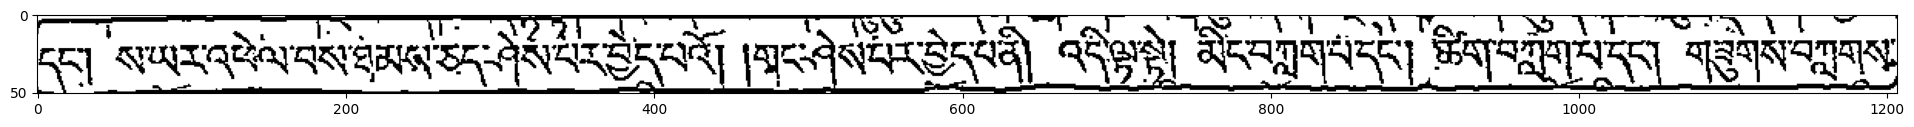

In [79]:
pad_img = layout_line_images[1]
show_image(pad_img)

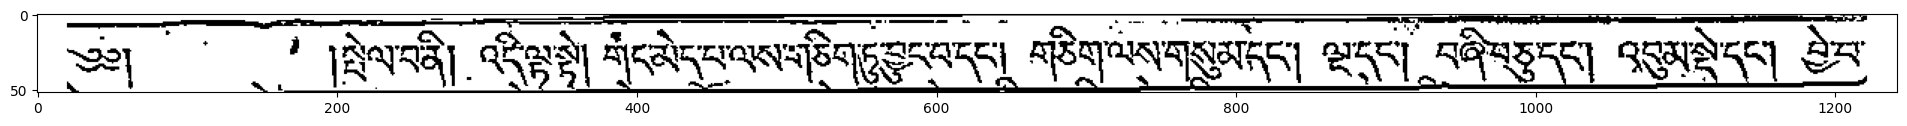

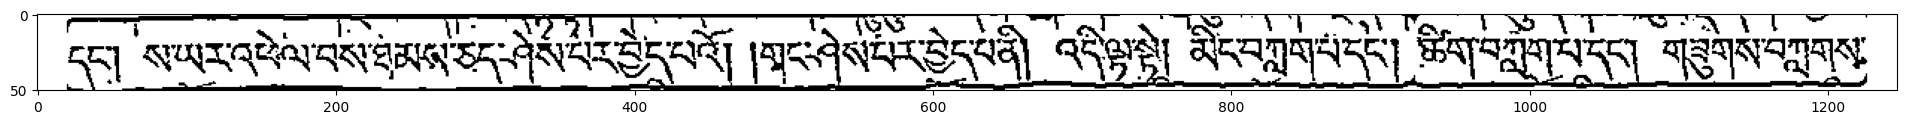

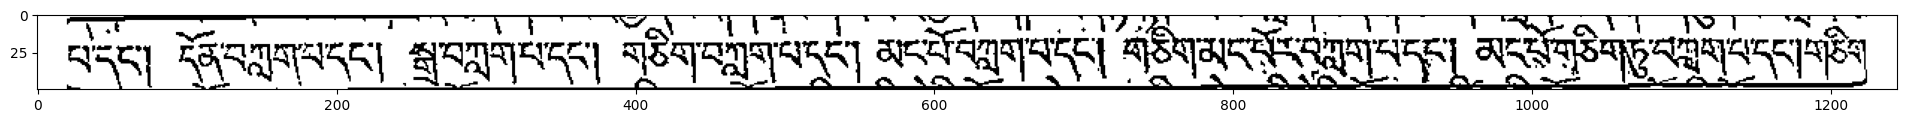

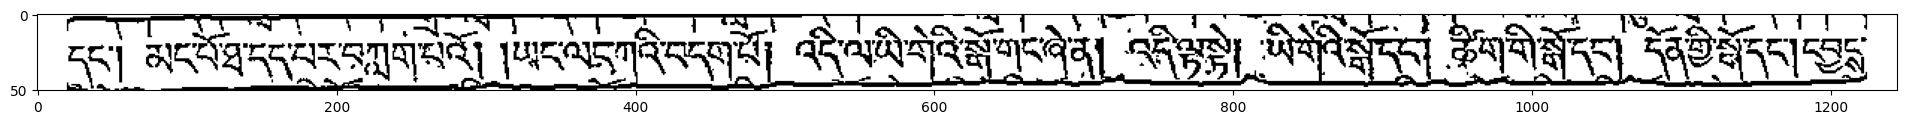

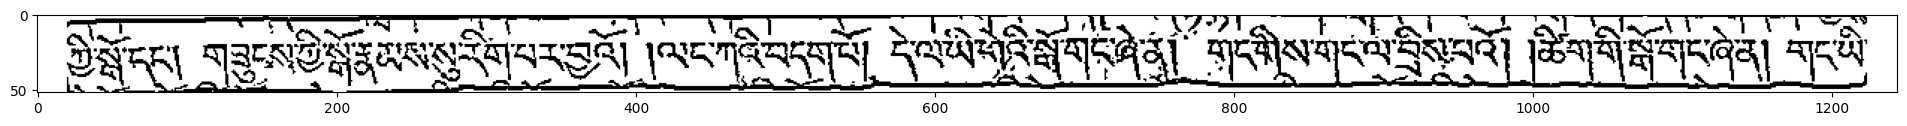

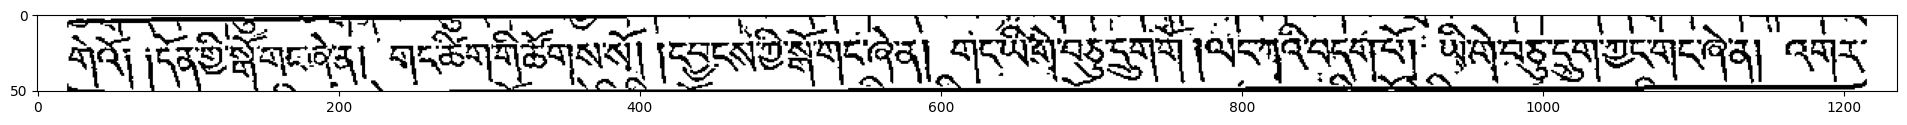

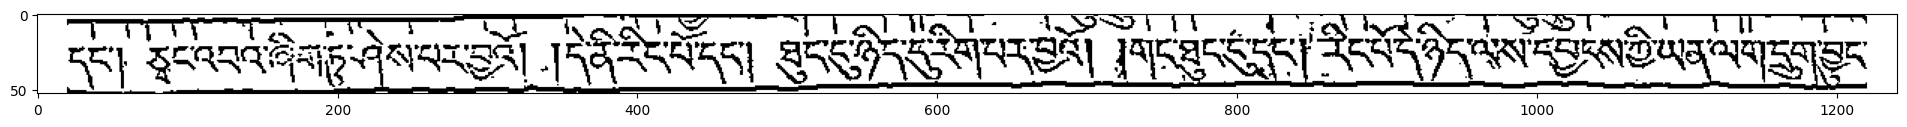

In [82]:
def post_pad_image(image: np.array, pad_width: int = 20) -> np.array:
    pad_patch = np.ones((image.shape[0], pad_width, image.shape[2]), dtype=np.uint8)
    pad_patch *= 255
    padded_img = np.hstack([pad_patch, image, pad_patch])

    return padded_img


layout_line_images = [post_pad_image(x) for x in layout_line_images]

for idx, img in enumerate(layout_line_images):
    show_image(layout_line_images[idx])


In [93]:
np_img_batch = [
            prepare_ocr_image2(
                x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
            ) for x in layout_line_images]
np_img_batch = np.array(np_img_batch, np.float32)

In [95]:
np_img_batch.shape

(7, 1, 80, 2000)

In [92]:
def run_keras_ocr(line_images: np.array):
    line_images = np.transpose(line_images, axes=[0, 3, 2, 1])
    line_images = line_images[:, :, :, 0]

    ocr_prediction = keras_inf.run(line_images)

    for line in ocr_prediction:
        print(line)

In [91]:
def run_onnx_inference(line_images: np.array):
    predicted_text, raw = ocr_inference.run(line_images, replace_tsheg=" ")
    
    for line in predicted_text:
        #text = text.replace(" ", "")
        #text = text.replace("§", " ")
        if line != "":
            print(line)

In [96]:
run_onnx_inference(np_img_batch)
run_keras_ocr(np_img_batch)


ValueError: Required inputs (['the_input']) are missing from input feed (['images']).

#### Run on All Images:


In [7]:
dataset_output = os.path.join(data_path, "RareStackDataset")
xml_out = os.path.join(dataset_output, "page")

create_dir(dataset_output)
create_dir(xml_out)

xml_exporter = PageXMLExporter(xml_out)

In [8]:
mismatch_pages = []

for idx, r_label_file in tqdm(enumerate(rare_stack_labels), total=len(rare_stack_labels)):
    idx = label_paths.index(r_label_file)
    ref_label = get_lines_from_page(label_paths[idx])

    try:
        image_name = os.path.basename(images[idx]).split(".")[0]
        _img = cv2.imread(images[idx])

    except FileExistsError as e:
        print.error(f"Cant read file at provided location: {images[idx]}, {e}")

    # layout_inference
    layout_data, _ = layout_inference.predict(_img)
    sorted_layout_data = layout_inference.sort_lines(layout_data, threshold=20, calculate=False)
    r_img = rotate_from_angle(_img, layout_data.rotation)

    layout_line_images = get_line_images_from_line_data(r_img, sorted_layout_data.lines, dilate_kernel=24, dilate_iterations=14, calculate_iterations=False)


    if len(ref_label) == len(layout_line_images):
        img_out = f"{dataset_output}/{image_name}.jpg"
        cv2.imwrite(img_out, r_img)
        xml_exporter.export(r_img, image_name, sorted_layout_data, ref_label)

    else:
        mismatch_pages.append(image_name)

print(f"Mismatched pages: {len(mismatch_pages)}")

mismatch_pages_out = f"{data_path}/rare_stack_page_mapping_mismatches.txt"

with open(mismatch_pages_out, "w", encoding="utf-8") as f:
    for p in mismatch_pages:
        f.write(f"{p}\n")

    

  0%|          | 0/10205 [00:00<?, ?it/s]

100%|██████████| 10205/10205 [5:06:34<00:00,  1.80s/it] 

Mismatched pages: 569
